# 04. Final GC-GP models: 10-fold cross-validation

**Purpose.** Evaluate the chosen GP model for each property with 10-fold
cross-validation. These are the final results for each property and the
inputs for the uncertainty analysis in `05_Uncertainty_Coverage.ipynb`.

**What this notebook produces** (in `Output_Data/final_gcgp_cv/<run name>/`)

* `<run>_all_cv_predictions.csv`: every prediction with its 95% interval, fold and set.
* `<run>_fold_metrics.csv` and `<run>_cv_statistics.csv`: per-fold and pooled metrics.
* `<run>_GP_CV_parity.png` / `.pdf`: pooled parity plot (600 dpi).
* `<run>_GP_CV_fold_r2.png` / `.pdf`: train and test R² for each fold.
* `final_cv_summary.csv`: one row per property.
* `results_summary.md`: the results written out in plain sentences.

**How cross-validation works here.** The molecules are shuffled (seed 42) and
cut into 10 folds. Each fold is held out once while the GP is trained on the
other 9. The "test" metrics pool the 10 held-out folds, so every molecule is
predicted exactly once by a model that never saw it. The "train" points stack
the in-fold predictions, so each molecule appears 9 times among them.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import pandas as pd

from gcgp.settings import checkCuratedData, describeSetup, outputFolder, setGlobalSeed
from gcgp.properties import PROPERTIES, PROPERTY_ORDER, loadPropertyData
from gcgp.finalConfig import RUN_NAMES, getGpConfig, getSettings, settingsTable
from gcgp.crossValidation import runGpCrossValidation
from gcgp.checkpoints import checkpointStatus

setGlobalSeed()
outputDir = outputFolder("final_gcgp_cv")
pd.set_option("display.precision", 3)
checkCuratedData()
print(describeSetup())
print(checkpointStatus())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42
Checkpoints   : resume from saved restarts; 14 saved in /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/checkpoints


**Checkpoints.** Every GP optimizer restart is saved in
`Output_Data/checkpoints/` as soon as it finishes. If the notebook stops (or is
rerun), finished restarts are loaded instead of refitted, so the run resumes
where it stopped and gives the same numbers. Set the environment variable
`GCGP_RESUME=0` to ignore the saved restarts and refit everything.

**Parallel restarts.** Restarts that still have to be fitted can run in
parallel worker processes: set the environment variable `GCGP_N_WORKERS`
(for example 4) before starting the kernel, or use
`bash scripts/run_notebooks.sh --workers 4`. The results are bit-for-bit the
same for any number of workers; `scripts/benchmark_gp_workers.py` shows which
number is fastest on your computer.

## 2. Data and model settings

Each property is read from its curated dataset in `Output_Data/curated_data/`
(written by `00_Data_Curation.ipynb`). Each property has one final model,
chosen in the kernel study (`03_Kernel_Comparison.ipynb`):

* `Method`: model form (2 = GP correction of the GC error, 4 = linear-mean GP).
* `Kernel` and `Anisotropic`: covariance function, and whether each input gets its own length scale.
* `Optimizer` and `Restarts`: SciPy optimizer and number of random restarts; the best converged restart is kept.
* `TrainLikelihood`: whether the noise term is fitted (if False it stays at 1e-5).

In [2]:
settings = pd.DataFrame(settingsTable())
settings.insert(1, "Molecules", [len(loadPropertyData(code)) for code in settings["Property"]])
settings

,Property,Molecules,Method,Kernel,Anisotropic,Optimizer,TrainLikelihood,Restarts
0,Tb,886,4,Matern32,True,L-BFGS-B,True,10
1,Tm,1839,4,RQ,False,L-BFGS-B,False,10
2,Pc,75,2,RQ,False,L-BFGS-B,False,10
3,Vc,69,4,Matern12,False,BFGS,False,10
4,Tc,70,4,Matern12,False,L-BFGS-B,False,10
5,Hvap,70,2,RQ,False,L-BFGS-B,False,10
6,logP,2978,4,Matern32,True,L-BFGS-B,True,5


## 3. Run cross-validation

For each property this prints one line per fold and then shows two figures: the
pooled parity plot (blue = in-fold training predictions, red = out-of-fold test
predictions) and a bar chart of R² per fold. A large gap between the blue and red
bars in a fold means the GP fits the training molecules much better than new
ones.

**Failed folds.** A fold is dropped from the pooled results, with a message,
when its GP cannot be used: no optimizer restart converged, TensorFlow reports a
failed Cholesky decomposition (which fills the predictions with NaNs), or any
other numerical error occurs. The run carries on with the remaining folds and
the plot title says how many folds were used. Dropped folds are listed in the
fold table and in the `Dropped_Folds` column of the summary.


Tb: method 4, Matern32 kernel
Fold 1/10: train R² = 0.844, test R² = 0.912, test RMSE = 21.11
Fold 2/10: train R² = 0.850, test R² = 0.861, test RMSE = 27.71
Fold 3/10: train R² = 0.856, test R² = 0.795, test RMSE = 26.46
Fold 4/10: train R² = 0.848, test R² = 0.874, test RMSE = 25.85
Fold 5/10: train R² = 0.848, test R² = 0.872, test RMSE = 26.07
Fold 6/10: train R² = 0.848, test R² = 0.879, test RMSE = 23.74
Fold 7/10: train R² = 0.859, test R² = 0.752, test RMSE = 29.10
Fold 8/10: train R² = 0.858, test R² = 0.771, test RMSE = 30.07
Fold 9/10: train R² = 0.850, test R² = 0.857, test RMSE = 26.46
Fold 10/10: train R² = 0.854, test R² = 0.828, test RMSE = 28.04


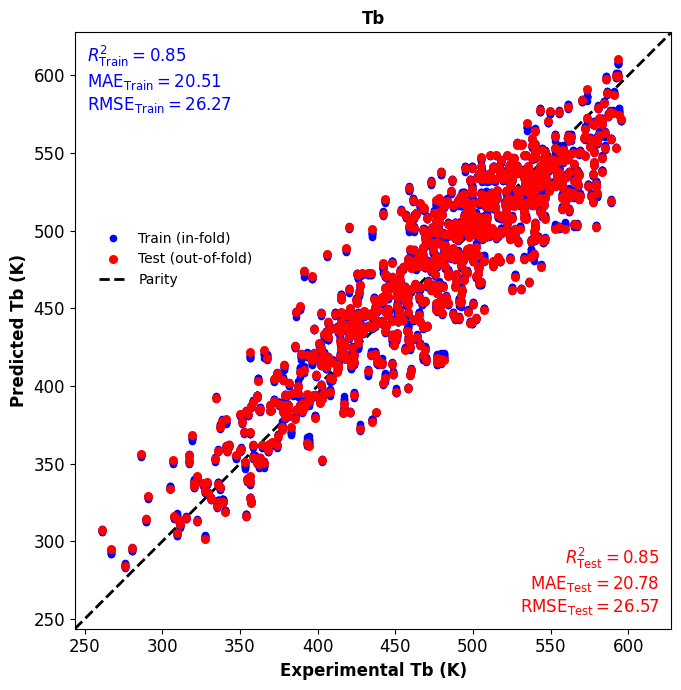

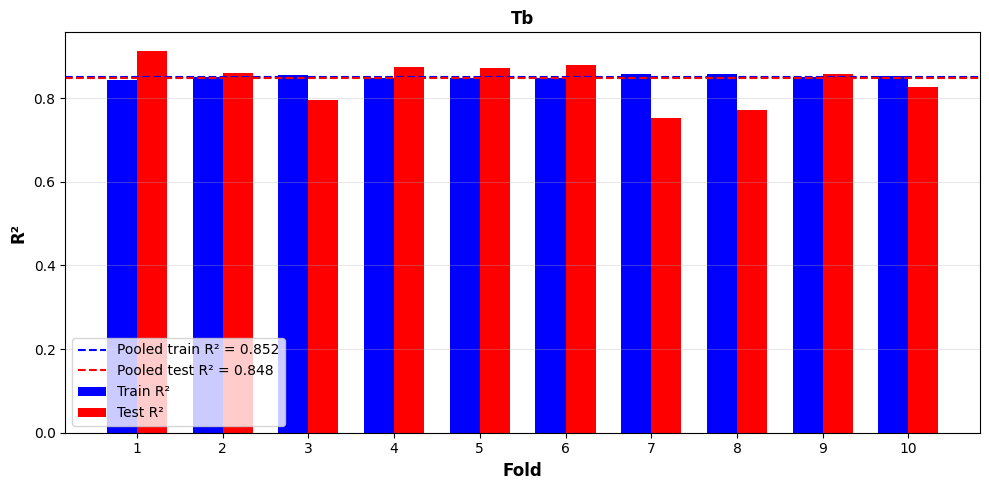


Tm: method 4, RQ kernel
Fold 1/10: train R² = 0.632, test R² = 0.602, test RMSE = 53.59
Fold 2/10: train R² = 0.631, test R² = 0.604, test RMSE = 54.76
Fold 3/10: train R² = 0.622, test R² = 0.660, test RMSE = 53.61
Fold 4/10: train R² = 0.632, test R² = 0.550, test RMSE = 55.55
Fold 5/10: train R² = 0.620, test R² = 0.665, test RMSE = 54.28
Fold 6/10: train R² = 0.635, test R² = 0.561, test RMSE = 54.90
Fold 7/10: train R² = 0.632, test R² = 0.595, test RMSE = 59.08
Fold 8/10: train R² = 0.627, test R² = 0.640, test RMSE = 55.10
Fold 9/10: train R² = 0.630, test R² = 0.600, test RMSE = 54.02
Fold 10/10: train R² = 0.628, test R² = 0.631, test RMSE = 54.90


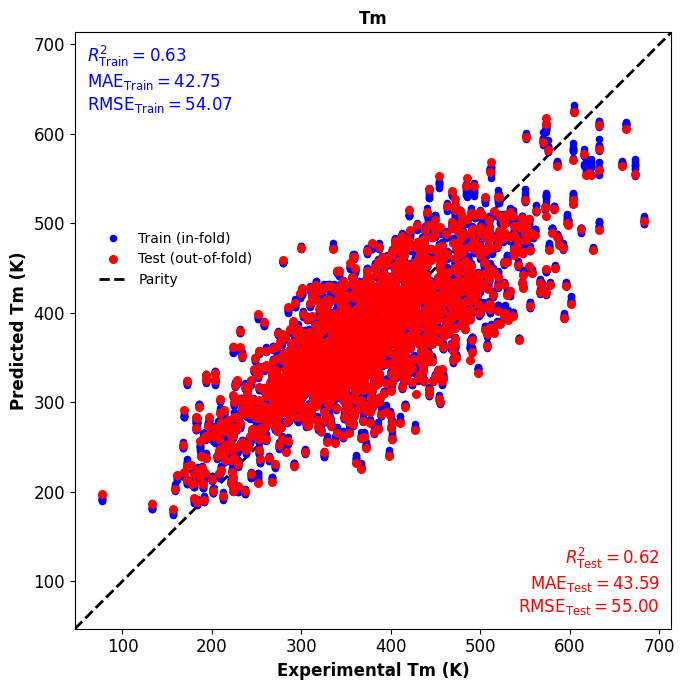

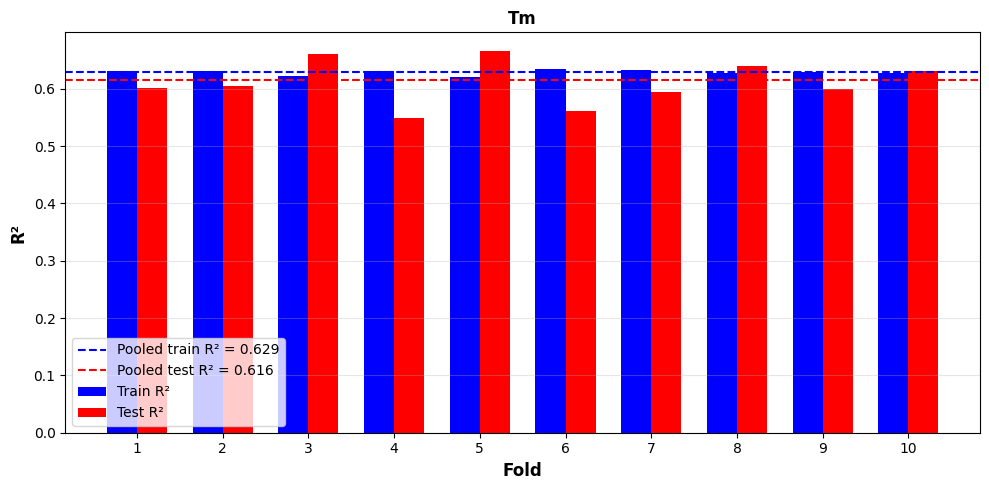


Pc: method 2, RQ kernel
Fold 1/10: train R² = 0.935, test R² = 0.802, test RMSE = 2.60
Fold 2/10: train R² = 0.826, test R² = 0.757, test RMSE = 6.64
Fold 3/10: train R² = 0.937, test R² = 0.719, test RMSE = 7.07
Fold 4/10: train R² = 0.979, test R² = 0.711, test RMSE = 5.46
Fold 5/10: train R² = 0.932, test R² = 0.930, test RMSE = 3.52
Fold 6/10: train R² = 0.892, test R² = 0.789, test RMSE = 7.98
Fold 7/10: train R² = 0.951, test R² = 0.459, test RMSE = 6.96
Fold 8/10: train R² = 0.817, test R² = 0.923, test RMSE = 4.77
Fold 9/10: train R² = 0.935, test R² = 0.905, test RMSE = 1.73
Fold 10/10: train R² = 0.854, test R² = 0.271, test RMSE = 5.35


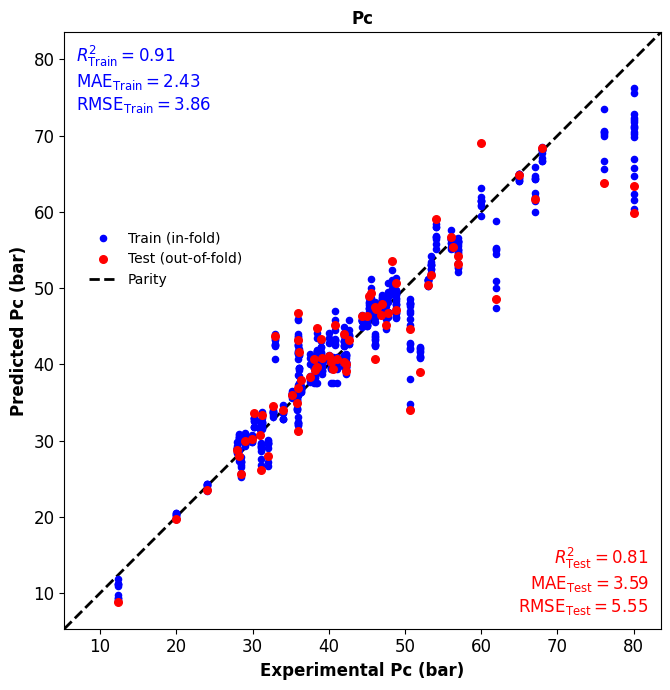

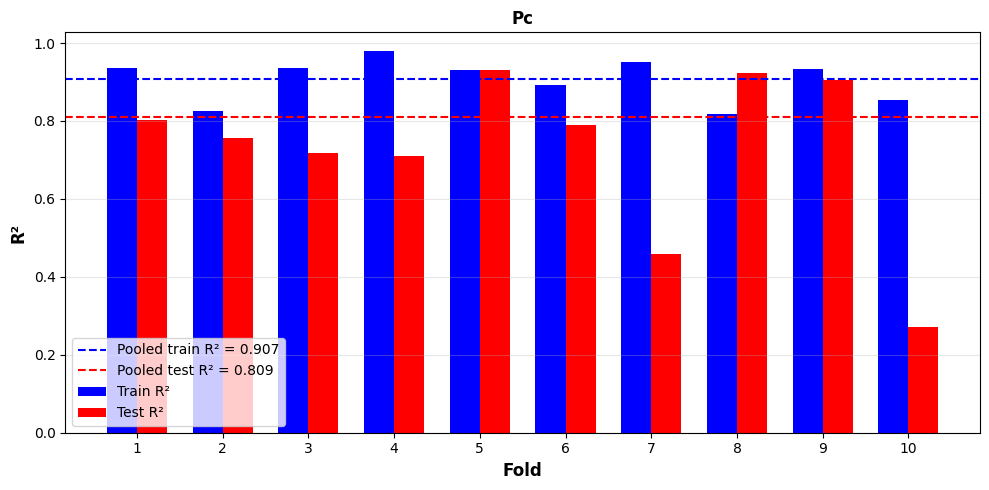


Vc: method 4, Matern12 kernel
Fold 1/10: train R² = 0.990, test R² = 0.994, test RMSE = 9.90
Fold 2/10: train R² = 0.991, test R² = 0.974, test RMSE = 12.10
Fold 3/10: train R² = 0.984, test R² = 0.991, test RMSE = 30.83
Fold 4/10: train R² = 0.991, test R² = 0.990, test RMSE = 12.55
Fold 5/10: train R² = 0.991, test R² = 0.928, test RMSE = 11.73
Fold 6/10: train R² = 0.990, test R² = 0.995, test RMSE = 10.83
Fold 7/10: train R² = 0.994, test R² = 0.912, test RMSE = 27.59
Fold 8/10: train R² = 0.991, test R² = 0.990, test RMSE = 18.76
Fold 9/10: train R² = 0.992, test R² = 0.955, test RMSE = 17.38
Fold 10/10: train R² = 0.991, test R² = 0.983, test RMSE = 15.75


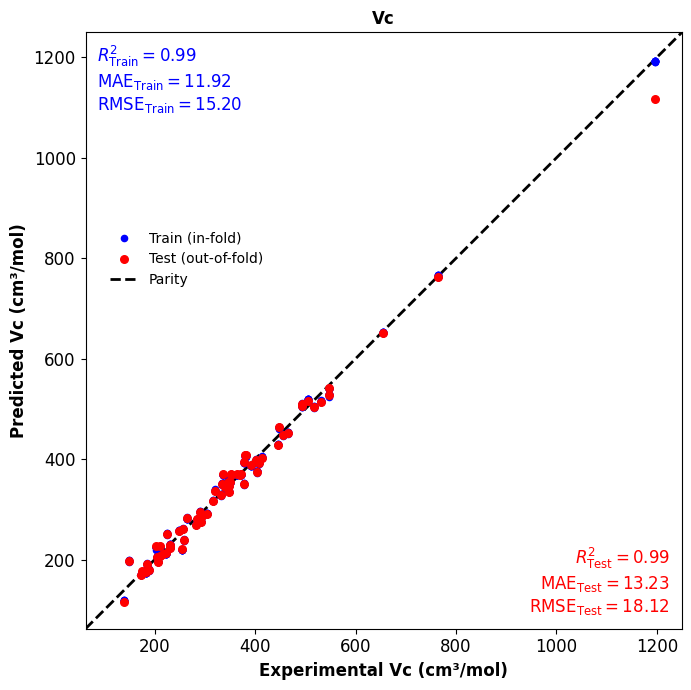

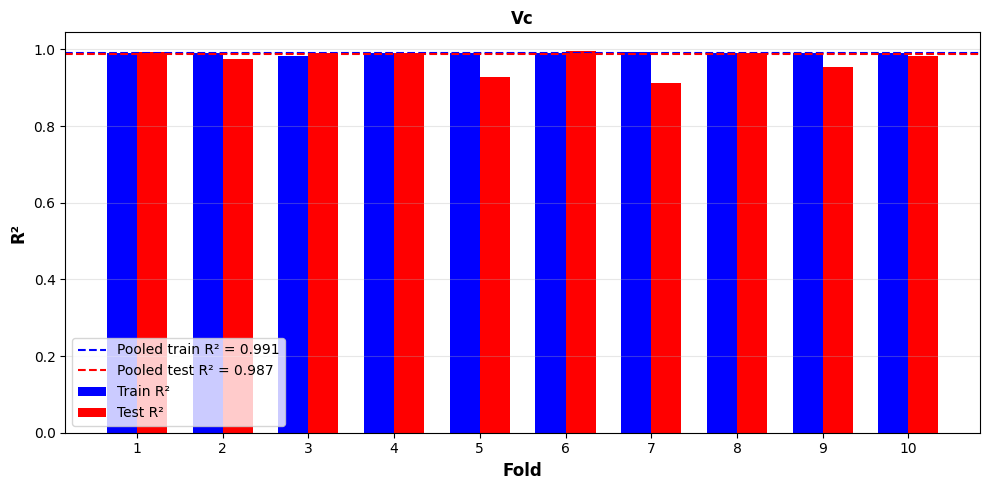


Tc: method 4, Matern12 kernel
Fold 1/10: train R² = 0.884, test R² = 0.908, test RMSE = 26.75
Fold 2/10: train R² = 0.890, test R² = 0.799, test RMSE = 26.98
Fold 3/10: train R² = 0.890, test R² = 0.762, test RMSE = 25.72
Fold 4/10: train R² = 0.879, test R² = 0.805, test RMSE = 19.22
Fold 5/10: train R² = 0.893, test R² = 0.699, test RMSE = 46.96
Fold 6/10: train R² = 0.899, test R² = 0.738, test RMSE = 41.01
Fold 7/10: train R² = 0.886, test R² = 0.804, test RMSE = 42.56
Fold 8/10: train R² = 0.872, test R² = 0.963, test RMSE = 21.21
Fold 9/10: train R² = 0.890, test R² = 0.802, test RMSE = 30.63
Fold 10/10: train R² = 0.884, test R² = 0.898, test RMSE = 28.23


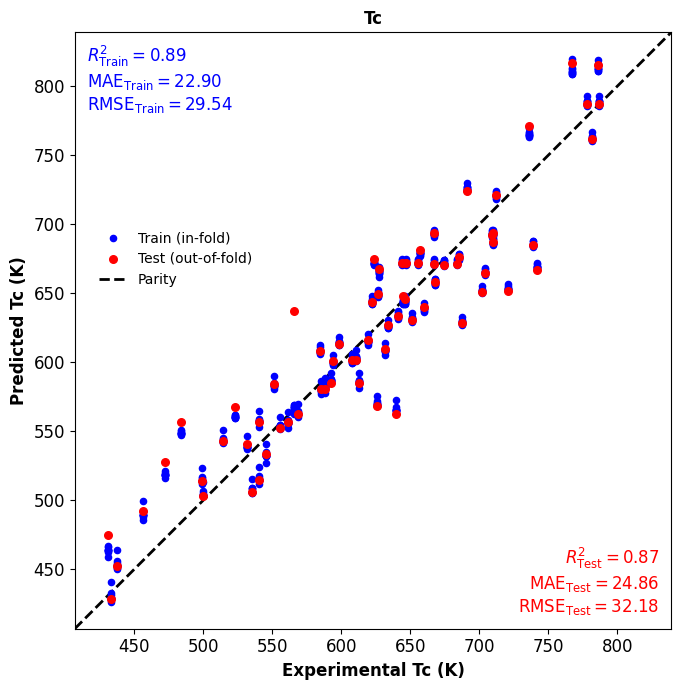

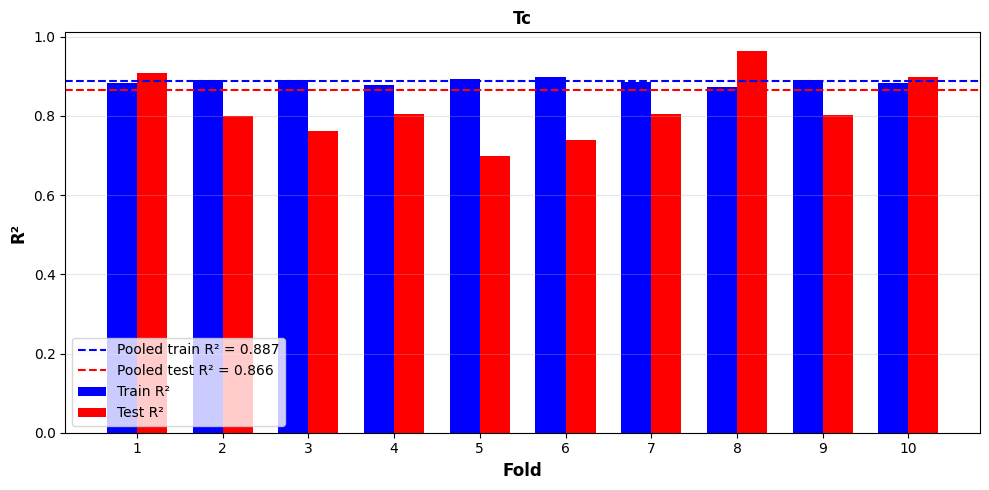


Hvap: method 2, RQ kernel
Fold 1/10: train R² = 0.964, test R² = 0.879, test RMSE = 1.89
Fold 2/10: train R² = 0.983, test R² = 0.896, test RMSE = 1.52
Fold 3/10: train R² = 0.981, test R² = 0.797, test RMSE = 1.68
Fold 4/10: train R² = 0.958, test R² = 0.948, test RMSE = 1.65
Fold 5/10: train R² = 0.974, test R² = 0.911, test RMSE = 1.67
Fold 6/10: train R² = 0.961, test R² = 0.921, test RMSE = 2.09
Fold 7/10: train R² = 0.982, test R² = 0.858, test RMSE = 2.26
Fold 8/10: train R² = 0.966, test R² = 0.858, test RMSE = 2.47
Fold 9/10: train R² = 0.970, test R² = 0.708, test RMSE = 2.73
Fold 10/10: train R² = 0.975, test R² = 0.988, test RMSE = 1.13


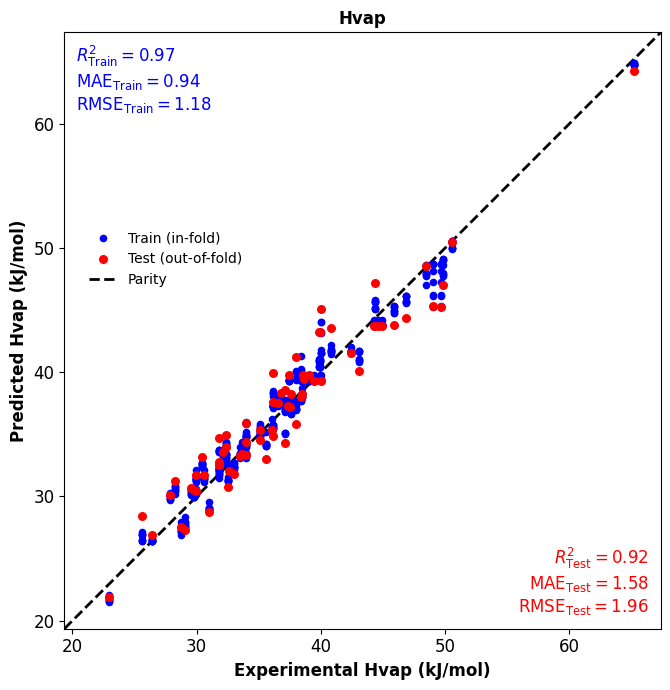

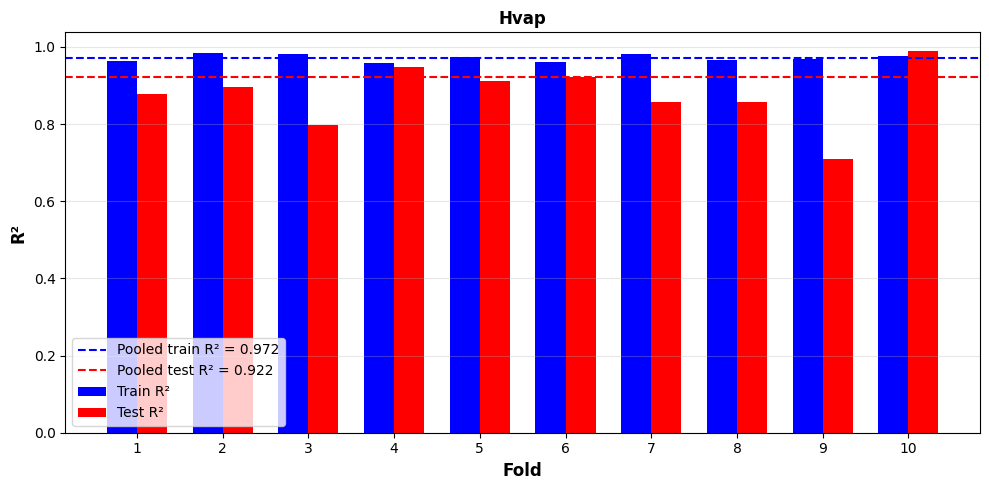


LogP: method 4, Matern32 kernel
Fold 1/10: train R² = 0.953, test R² = 0.886, test RMSE = 0.66
Fold 2/10: train R² = 0.989, test R² = 0.931, test RMSE = 0.63
Fold 3/10: train R² = 0.989, test R² = 0.902, test RMSE = 0.61
Fold 4/10: train R² = 0.940, test R² = 0.812, test RMSE = 0.83
Fold 5/10: train R² = 0.989, test R² = 0.881, test RMSE = 0.65
Fold 6/10: train R² = 0.990, test R² = 0.879, test RMSE = 0.66
Fold 7/10: train R² = 0.904, test R² = 0.832, test RMSE = 0.74
Fold 8/10: train R² = 0.989, test R² = 0.923, test RMSE = 0.60
Fold 9/10: train R² = 0.990, test R² = 0.834, test RMSE = 0.75
Fold 10/10: train R² = 0.988, test R² = 0.898, test RMSE = 0.59


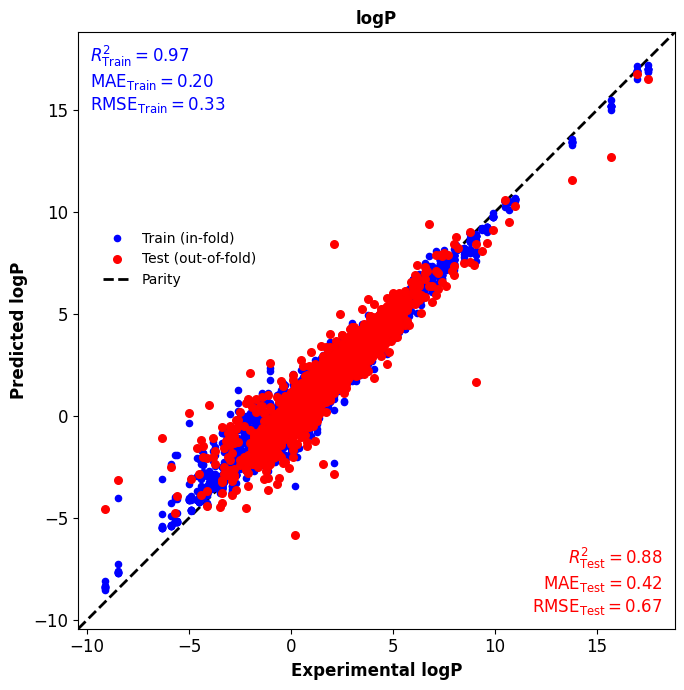

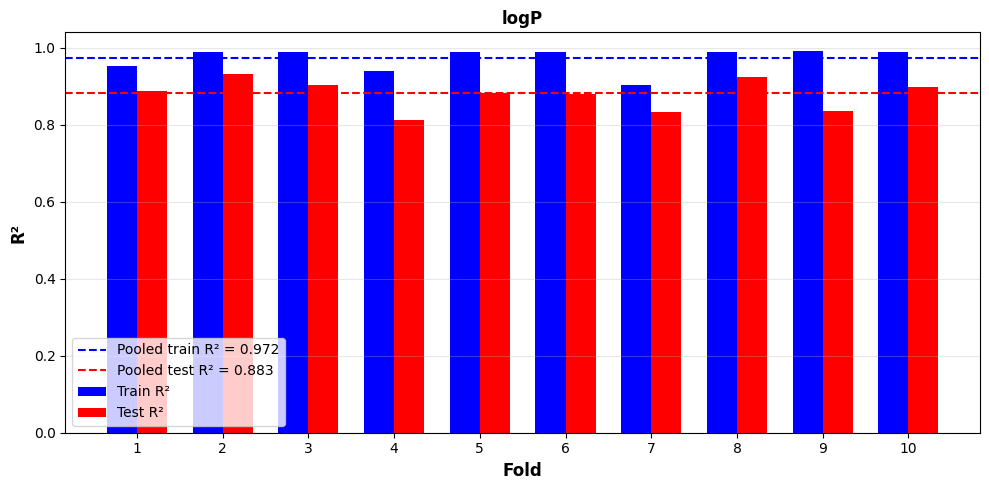

In [3]:
summaries = []
for code in PROPERTY_ORDER:
    info = PROPERTIES[code]
    settings = getSettings(code)
    runName = RUN_NAMES[code]
    print(f"\n{runName}: method {settings['method']}, {settings['kernel']} kernel")
    result = runGpCrossValidation(
        runName, loadPropertyData(code), info["featureCols"], info["targetCol"], getGpConfig(code),
        settings["retrainGp"], outputDir, info["xLabel"], info["yLabel"], plotTitle=code)
    if result is not None:
        summaries.append(result["summary"])

## 4. Results

### 4.1 Summary table

`Overall_Test_*` values pool the out-of-fold predictions. `Mean_Test_R2 ±
Std_Test_R2` shows how much R² varies from fold to fold. `CI_Test_Outside_Frac`
is the share of molecules whose experimental value falls outside the 95%
interval (the target is about 0.05).

In [4]:
summaryDf = pd.DataFrame(summaries)
summaryDf.to_csv(outputDir / "final_cv_summary.csv", index=False)

summaryDf[["Property", "N_Molecules", "N_Successful_Folds", "N_Failed_Folds", "Overall_Train_R2",
           "Overall_Test_R2", "Mean_Test_R2", "Std_Test_R2", "Overall_Test_MAE",
           "Overall_Test_RMSE", "CI_Test_Outside_Frac"]]

,Property,N_Molecules,N_Successful_Folds,N_Failed_Folds,Overall_Train_R2,Overall_Test_R2,Mean_Test_R2,Std_Test_R2,Overall_Test_MAE,Overall_Test_RMSE,CI_Test_Outside_Frac
0,Tb,886,10,0,0.852,0.848,0.840,0.052,20.780,26.566,0.062
1,Tm,1839,10,0,0.629,0.616,0.611,0.038,43.589,55.000,0.053
2,Pc,75,10,0,0.907,0.809,0.727,0.211,3.590,5.550,0.107
3,Vc,69,10,0,0.991,0.987,0.971,0.030,13.233,18.116,0.072
4,Tc,70,10,0,0.887,0.866,0.818,0.082,24.863,32.183,0.100
5,Hvap,70,10,0,0.972,0.922,0.876,0.079,1.585,1.962,0.071
6,LogP,2978,10,0,0.972,0.883,0.878,0.040,0.422,0.675,0.058


## 5. Summary of the results

The text below is written from the summary table of this run. When notebook 01
has been run, the fitted GC baseline is added for comparison. Note that the
baseline is scored on one 80/20 split, while the GP numbers pool ten folds.
Because training points appear nine times each in the parity plots, the test
(red) points are the fair measure of accuracy. The prediction files are used
next in `05_Uncertainty_Coverage.ipynb`.

In [5]:
from gcgp.narrative import describeCrossValidation, showAndSave
from gcgp.settings import OUTPUT_DIR

baselinePath = OUTPUT_DIR / "jrgc_baseline" / "JRGC_statistical_metrics.csv"
baselineDf = pd.read_csv(baselinePath) if baselinePath.exists() else None

showAndSave(describeCrossValidation(summaryDf, baselineDf), outputDir / "results_summary.md");

## Final GC-GP models, cross-validation: results

- **Tb** (886 molecules, 10 of 10 folds used): pooled test R² = 0.848 (fold mean 0.840 ± 0.052), MAE = 20.78 K, RMSE = 26.57 K; 93.8% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 45.19 K on its own 80/20 split of the JRGC set.
- **Tm** (1839 molecules, 10 of 10 folds used): pooled test R² = 0.616 (fold mean 0.611 ± 0.038), MAE = 43.59 K, RMSE = 55.00 K; 94.7% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 64.57 K on its own 80/20 split of the JRGC set.
- **Pc** (75 molecules, 10 of 10 folds used): pooled test R² = 0.809 (fold mean 0.727 ± 0.211), MAE = 3.59 bar, RMSE = 5.55 bar; 89.3% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 6.48 bar on its own 80/20 split of the JRGC set.
- **Vc** (69 molecules, 10 of 10 folds used): pooled test R² = 0.987 (fold mean 0.971 ± 0.030), MAE = 13.23 cm³/mol, RMSE = 18.12 cm³/mol; 92.8% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 11.51 cm³/mol on its own 80/20 split of the JRGC set.
- **Tc** (70 molecules, 10 of 10 folds used): pooled test R² = 0.866 (fold mean 0.818 ± 0.082), MAE = 24.86 K, RMSE = 32.18 K; 90.0% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 63.53 K on its own 80/20 split of the JRGC set.
- **ΔHvap** (70 molecules, 10 of 10 folds used): pooled test R² = 0.922 (fold mean 0.876 ± 0.079), MAE = 1.58 kJ/mol, RMSE = 1.96 kJ/mol; 92.9% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 7.69 kJ/mol on its own 80/20 split of the JRGC set.
- **log P** (2978 molecules, 10 of 10 folds used): pooled test R² = 0.883 (fold mean 0.878 ± 0.040), MAE = 0.422, RMSE = 0.675; 94.2% of molecules inside the 95% interval. For comparison, the fitted GC baseline has test RMSE = 0.713 on its own 80/20 split of the JRGC set.
